# Image Classification using `CIFAR-10` dataset

![image.png](attachment:a1a86ad8-6fae-45e8-a536-68b2d345fdc0.png)

### Import certain libraries

In [1]:
import numpy as np
import pandas as pd

import os

import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras import datasets, layers, models, callbacks

In [2]:
import tensorflow as tf
print(tf.__version__)

2.21.0


In [3]:
%pip install tensorflow

Note: you may need to restart the kernel to use updated packages.


In [4]:
### Get the current working directory
os.getcwd()

'c:\\Users\\Sonal Thorat\\Desktop\\Intellipaat python code\\INTELLIPAAT TOPICS FILES\\CIFAR-10 MODEL'

## Download and prepare the `CIFAR-10` dataset

*   The CIFAR10 dataset contains **60,000 color images** in `10 classes`, with `6,000 images` in each class.
*   Dataset is divided into **50,000 training images** and **10,000 testing** images.
*   Classes are mutually exclusive and there is no overlap between them
*   There is no overlap between `automobiles` and `trucks`. Truck class contains only `big` trucks

In [5]:
(train_images, train_labels), (test_images, test_labels) = datasets.cifar10.load_data() #loading the CIFAR-10 dataset directly from tf.keras

C:\mypython\Lib\site-packages\keras\src\datasets\cifar.py:18: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  d = cPickle.load(f, encoding="bytes")


In [6]:
train_images.shape

(50000, 32, 32, 3)

In [7]:
test_images.shape

(10000, 32, 32, 3)

### Let us plot one of the `training` images from CIFAR-10 dataset

In [8]:
sample_image_1 = train_images[12]
sample_image_1

array([[[164, 215, 244],
        [162, 212, 240],
        [162, 212, 240],
        ...,
        [157, 210, 237],
        [153, 208, 235],
        [153, 203, 234]],

       [[168, 218, 245],
        [166, 215, 242],
        [166, 215, 242],
        ...,
        [164, 212, 238],
        [160, 209, 236],
        [158, 205, 235]],

       [[172, 220, 246],
        [170, 217, 243],
        [171, 218, 244],
        ...,
        [168, 212, 238],
        [165, 208, 235],
        [163, 207, 236]],

       ...,

       [[123, 160, 105],
        [117, 154, 102],
        [112, 149,  99],
        ...,
        [117, 136, 100],
        [ 95, 115,  79],
        [120, 149, 100]],

       [[120, 156, 100],
        [116, 151,  99],
        [112, 147,  96],
        ...,
        [126, 149, 110],
        [120, 144, 103],
        [120, 152, 101]],

       [[121, 154,  96],
        [120, 152,  99],
        [116, 148,  97],
        ...,
        [124, 152, 108],
        [124, 154, 107],
        [120, 154, 100]]

In [9]:
sample_image_1.shape

(32, 32, 3)

In [10]:
print("Shape of the sample training image:", sample_image_1.shape)

Shape of the sample training image: (32, 32, 3)


In [11]:
### Extract the R, G, B channels separately
R = sample_image_1[:, :, 0] #to extract one of the color channels from a color image --> RED
G = sample_image_1[:, :, 1] #to extract one of the color channels from a color image --> GREEN
B = sample_image_1[:, :, 2] #to extract one of the color channels from a color image --> BLUE

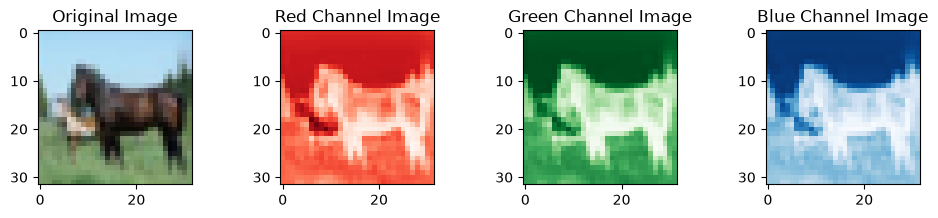

In [12]:
#### Display the original image alogn with `RGB` channels separately
### Setting up the canvas ready
fig, axs = plt.subplots(nrows=1, ncols=4, figsize = (12,2))

### Original Image
axs[0].imshow(sample_image_1)
axs[0].set_title("Original Image")

### Red Channel Image
axs[1].imshow(R, cmap='Reds')
axs[1].set_title("Red Channel Image")

### Green Channel Image
axs[2].imshow(G, cmap='Greens')
axs[2].set_title("Green Channel Image")

### Blue Channel Image
axs[3].imshow(B, cmap='Blues')
axs[3].set_title("Blue Channel Image")

plt.show()

### Let us plot a few more but this time with class/label as title

In [13]:
np.unique(train_labels)

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype=uint8)

- Class/catgory is `label encoded (LE)`

In [14]:
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

In [15]:
class_names

['airplane',
 'automobile',
 'bird',
 'cat',
 'deer',
 'dog',
 'frog',
 'horse',
 'ship',
 'truck']

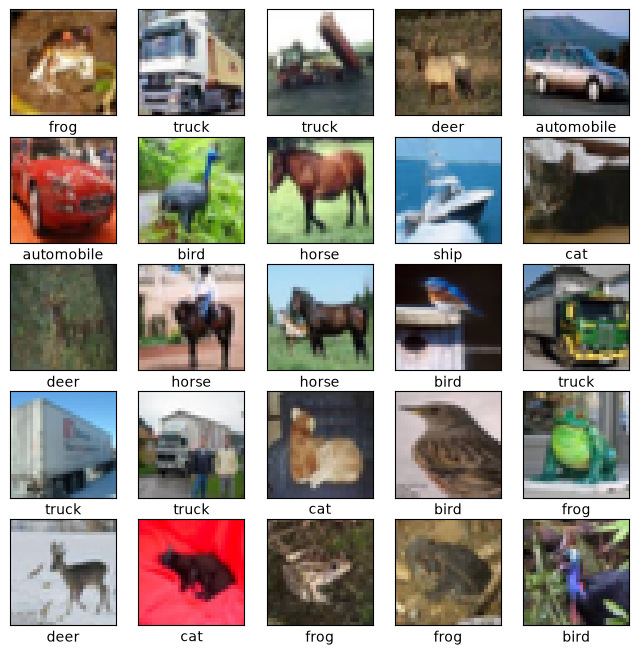

In [16]:
plt.figure(figsize = (8,8))

for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)

    plt.imshow(train_images[i]) #plot the images from training set from 0 to 24 indices
    plt.xlabel(class_names[train_labels[i][0]]) #tagging the class label to the respective class names using class_names list

### TASK: Try improvising this code to plot `n random images` from both `training` and `testing` sets respectively

### Understanding the `convolution` or `filtering` operation

In [17]:
from PIL import Image, ImageChops #read about Pillow library
import requests
from io import BytesIO

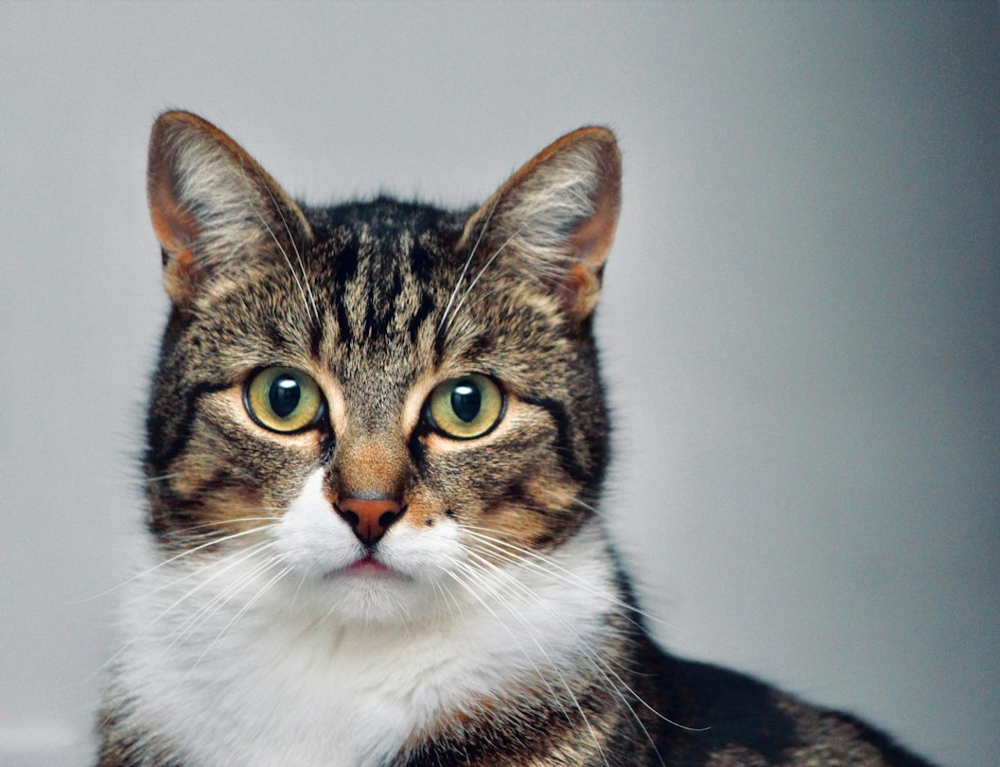

In [18]:
# image_url = 'https://images.unsplash.com/photo-1529778873920-4da4926a72c2?q=80&w=736&auto=format&fit=crop&ixlib=rb-4.1.0&ixid=M3wxMjA3fDB8MHxwaG90by1wYWdlfHx8fGVufDB8fHx8fA%3D%3D'
# image_url = 'https://preview.redd.it/timepass-click-v0-7f08yp0nrcce1.jpg?width=1080&crop=smart&auto=webp&s=68cdc4aa5088ffc54ba952fb9ad7fbe7496be53a'
image_url = 'https://images.unsplash.com/photo-1583795128727-6ec3642408f8?q=80&w=1057&auto=format&fit=crop&ixlib=rb-4.1.0&ixid=M3wxMjA3fDB8MHxwaG90by1wYWdlfHx8fGVufDB8fHx8fA%3D%3D'
response = requests.get(image_url)
img = Image.open(BytesIO(response.content))
display(img)

In [19]:
### To get the size of the CAT's image
width, height = img.size
print("Width of the CAT's image:", width, "px")
print("Height of the CAT's image:", height, "px")

Width of the CAT's image: 1057 px
Height of the CAT's image: 811 px


In [20]:
1057*811

857227

In [21]:
### Let us resize the images from its original size to 200px by 200px
img_resized = img.resize((200, 200))
width1, height1 = img_resized.size
print("Width of resized CAT's image:", width1, "px")
print("Height of resized CAT's image:", height1, "px")

Width of resized CAT's image: 200 px
Height of resized CAT's image: 200 px


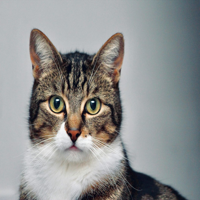

In [22]:
display(img_resized)

In [23]:
### Convert the resized image into an array
cat_img_array = np.array(img_resized)
cat_img_array

array([[[183, 182, 187],
        [182, 182, 187],
        [182, 184, 188],
        ...,
        [ 64,  79,  91],
        [ 63,  77,  86],
        [ 64,  80,  91]],

       [[182, 185, 188],
        [180, 184, 186],
        [180, 186, 188],
        ...,
        [ 65,  79,  89],
        [ 64,  77,  86],
        [ 64,  78,  91]],

       [[181, 185, 188],
        [179, 184, 187],
        [178, 186, 188],
        ...,
        [ 68,  81,  90],
        [ 67,  77,  88],
        [ 64,  77,  92]],

       ...,

       [[177, 180, 184],
        [174, 178, 183],
        [176, 180, 184],
        ...,
        [106, 120, 127],
        [ 99, 118, 123],
        [ 97, 120, 123]],

       [[172, 177, 181],
        [172, 177, 183],
        [175, 179, 183],
        ...,
        [106, 119, 127],
        [100, 119, 124],
        [ 99, 118, 121]],

       [[172, 175, 181],
        [170, 175, 182],
        [172, 176, 182],
        ...,
        [108, 118, 129],
        [103, 118, 126],
        [101, 115, 122]]

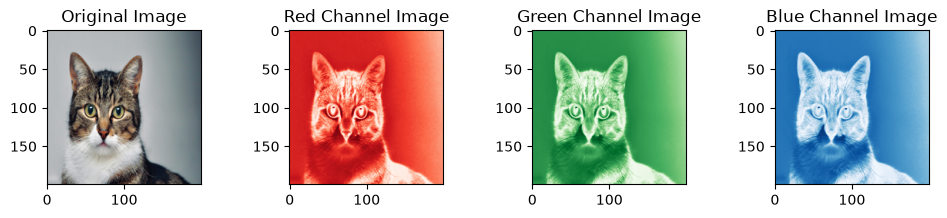

In [24]:
### Extract the R,G,B channels separately
R = cat_img_array[:, :, 0] #to extract one of the color channels from a color image --> RED
G = cat_img_array[:, :, 1] #to extract one of the color channels from a color image --> GREEN
B = cat_img_array[:, :, 2] #to extract one of the color channels from a color image --> BLUE


### Setting up the canvas ready
fig, axs = plt.subplots(nrows=1, ncols=4,figsize=(12,2))

### Original Image
axs[0].imshow(cat_img_array)
axs[0].set_title("Original Image")

### Red Channel Image
axs[1].imshow(R, cmap = 'Reds')
axs[1].set_title("Red Channel Image")

### Green Channel Image
axs[2].imshow(G, cmap = 'Greens')
axs[2].set_title("Green Channel Image")

### Blue Channel Image
axs[3].imshow(B, cmap = 'Blues')
axs[3].set_title("Blue Channel Image")

plt.show()

### Let us visualize this cat in the designated CIFAR-10 dataset image size 32 x 32 pixels

In [25]:
img_resized_32 = img.resize((32, 32))
width2, height2 = img_resized_32.size
print("Width of resized CAT's image:", width2, "px")
print("Height of resized CAT's image:", height2, "px")

Width of resized CAT's image: 32 px
Height of resized CAT's image: 32 px


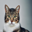

In [26]:
display(img_resized_32)

### Convert original `CAT` image to `grayscale` image

In [27]:
# pip install opencv-python

In [28]:
import cv2
print(cv2.__version__)

5.0.0


In [29]:
gray_cat = cv2.cvtColor(cat_img_array, cv2.COLOR_RGB2GRAY)
display(gray_cat)

array([[183, 183, 184, ...,  76,  74,  76],
       [184, 183, 184, ...,  76,  74,  75],
       [184, 183, 184, ...,  78,  75,  75],
       ...,
       [180, 177, 179, ..., 117, 113, 113],
       [176, 176, 178, ..., 116, 114, 113],
       [175, 174, 175, ..., 116, 114, 112]], shape=(200, 200), dtype=uint8)

In [30]:
gray_cat.min(), gray_cat.max()

(np.uint8(2), np.uint8(253))

- color intensity values are from the range of 0 - 255

### Let us visualize the original grayscale cat with different filters applied on it

In [31]:
filters = {
    'Original': gray_cat, #original grayscale image
    'SOBEL X': cv2.Sobel(gray_cat, cv2.CV_64F, 1, 0, ksize=3), #SOBEL X operator
    'SOBEL Y': cv2.Sobel(gray_cat, cv2.CV_64F, 0, 1, ksize=3), #SOBEL Y operator
    'Laplacian': cv2.Laplacian(gray_cat, cv2.CV_64F), #Laplacian Operator
    'Sharpen': cv2.filter2D(gray_cat, -1, kernel = np.array([[0,-1,0], [-1,5,-1], [0,-1,0]])), #Sharpen Operator
    'Gaussian Blur': cv2.GaussianBlur(gray_cat, (5,5), 0) #Gaussian Blur Operator
}

In [32]:
filters

{'Original': array([[183, 183, 184, ...,  76,  74,  76],
        [184, 183, 184, ...,  76,  74,  75],
        [184, 183, 184, ...,  78,  75,  75],
        ...,
        [180, 177, 179, ..., 117, 113, 113],
        [176, 176, 178, ..., 116, 114, 113],
        [175, 174, 175, ..., 116, 114, 112]], shape=(200, 200), dtype=uint8),
 'SOBEL X': array([[  0.,   2.,   8., ..., -10.,  -2.,   0.],
        [  0.,   1.,  10., ..., -12.,  -5.,   0.],
        [  0.,   1.,  10., ..., -13., -10.,   0.],
        ...,
        [  0.,  -1.,   5., ..., -18., -13.,   0.],
        [  0.,   3.,  11., ..., -16., -14.,   0.],
        [  0.,   4.,  14., ..., -14., -14.,   0.]], shape=(200, 200)),
 'SOBEL Y': array([[  0.,   0.,   0., ...,   0.,   0.,   0.],
        [  2.,   1.,   2., ...,   8.,   3.,   0.],
        [  0.,   1.,   0., ...,   5.,   4.,   2.],
        ...,
        [-32., -29., -23., ...,   2.,   1.,   0.],
        [-16., -15., -11., ...,  -2.,   0.,   0.],
        [  0.,   0.,   0., ...,   0.,   0.,

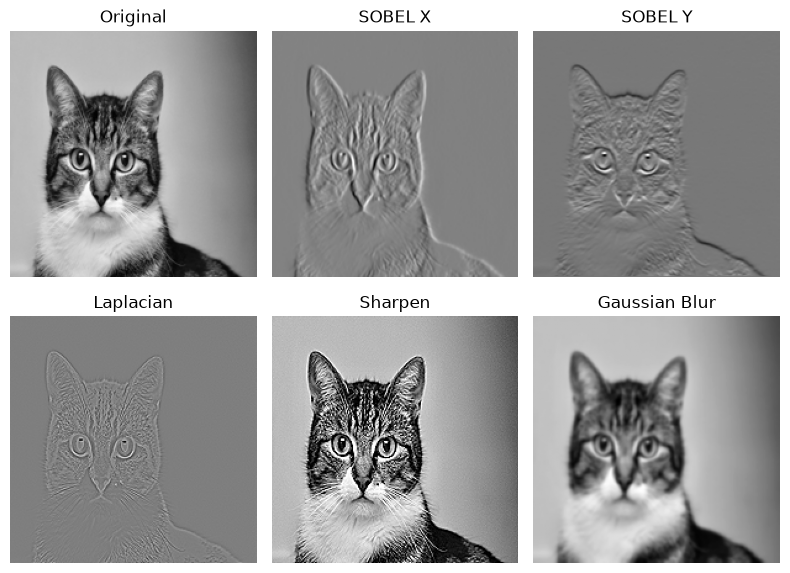

In [33]:
### plot the results of the above filters
plt.figure(figsize = (8,6))

for i, (title, img) in enumerate(filters.items(),1):
    plt.subplot(2,3,i)
    cmap = 'gray'if len(img.shape)==2 else None
    plt.imshow(img, cmap=cmap)
    plt.title(title)
    plt.axis('off')

plt.tight_layout()
plt.show()

# Let us build `CNN` baseline model

- leveraging `CIFAR-10` dataset

![image.png](attachment:f5e12781-f6f0-406b-9a40-30cd8d908360.png)

- Conv1D is used for the text
- **Conv2D is used for the images** - this is in our syllabus
- Conv3D is used for the videos/motion --> MRI/CT scan videos

In [34]:
# Define Data Augmentation
data_augmentation = tf.keras.Sequential([
  layers.RandomFlip("horizontal"),
  layers.RandomRotation(0.1),
  layers.RandomZoom(0.1),
])

model = models.Sequential([layers.Input(shape=(32, 32, 3))]) # model for the improved CNN

In [35]:
model

<Sequential name=sequential_1, built=False>

In [36]:
# Add Data Augmentation as the first layer
model.add(data_augmentation)

# Block 1
model.add(layers.Conv2D(32, (3,3), activation='relu', padding='same'))
model.add(layers.BatchNormalization())
model.add(layers.Conv2D(32, (3,3), activation='relu', padding='same'))
model.add(layers.BatchNormalization())
model.add(layers.MaxPool2D((2,2)))
model.add(layers.Dropout(0.15))

# Block 2
model.add(layers.Conv2D(64, (3,3), activation='relu', padding='same'))
model.add(layers.BatchNormalization())
model.add(layers.Conv2D(64, (3,3), activation='relu', padding='same'))
model.add(layers.BatchNormalization())
model.add(layers.MaxPool2D((2,2)))
model.add(layers.Dropout(0.25))

# Block 3
model.add(layers.Conv2D(128, (3,3), activation='relu', padding='same'))
model.add(layers.BatchNormalization())
model.add(layers.Conv2D(128, (3,3), activation='relu', padding='same'))
model.add(layers.BatchNormalization())
model.add(layers.MaxPool2D((2,2)))
model.add(layers.Dropout(0.35))

# Block 4
model.add(layers.Conv2D(256, (3,3), activation='relu', padding='same'))
model.add(layers.BatchNormalization())
model.add(layers.Conv2D(256, (3,3), activation='relu', padding='same'))
model.add(layers.BatchNormalization())
model.add(layers.MaxPool2D((2,2)))
model.add(layers.Dropout(0.4))

In [37]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 4, 4, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 4, 4, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 1,176,096 (4.49 MB)

 Trainable params: 1,174,176 (4.48 MB)

 Non-trainable params: 1,920 (7.50 KB)

### Let us add `ANN` block on top of the `CNN` block

In [38]:
model.add(layers.Flatten())
model.add(layers.Dense(256, activation='relu'))
model.add(layers.BatchNormalization())
model.add(layers.Dropout(0.4))
model.add(layers.Dense(10)) # Output layer for 10 classes

In [39]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 4, 4, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 4, 4, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 1,442,090 (5.50 MB)

 Trainable params: 1,439,658 (5.49 MB)

 Non-trainable params: 2,432 (9.50 KB)

- Even a very simple `CNN` model has `52.87K` parameters

### Compile and train the model


In [40]:
model.compile(optimizer='adam',
                 loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
                 metrics=['accuracy'])

# Callbacks for better training
early_stopping = callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)
reduce_lr = callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6)
model_checkpoint = callbacks.ModelCheckpoint(
    'best_cifar10_model.keras',
    monitor='val_loss',
    save_best_only=True,
    mode='min'
)

In [41]:
# Normalize the images to [0, 1] for better convergence
train_images = train_images.astype('float32') / 255.0
test_images = test_images.astype('float32') / 255.0

history = model.fit(train_images, train_labels,
                    epochs=50,
                    validation_split=0.1,
                    callbacks=[model_checkpoint, early_stopping, reduce_lr])

# Evaluate the checkpoint with the best validation loss.
model = tf.keras.models.load_model('best_cifar10_model.keras')

test_loss, test_accuracy = model.evaluate(test_images, test_labels, verbose=2)
print(f"Best-checkpoint test accuracy: {test_accuracy:.2%}")

Epoch 1/50


   1/1407 ━━━━━━━━━━━━━━━━━━━━ 13:38:51 35s/step - accuracy: 0.0625 - loss: 3.8922

   2/1407 ━━━━━━━━━━━━━━━━━━━━ 5:15 224ms/step - accuracy: 0.0703 - loss: 3.8541  

   3/1407 ━━━━━━━━━━━━━━━━━━━━ 6:07 262ms/step - accuracy: 0.0712 - loss: 3.7882

   4/1407 ━━━━━━━━━━━━━━━━━━━━ 6:10 264ms/step - accuracy: 0.0671 - loss: 3.7409

...

1405/1407 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - accuracy: 0.8661 - loss: 0.3908

1406/1407 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - accuracy: 0.8661 - loss: 0.3908

1407/1407 ━━━━━━━━━━━━━━━━━━━━ 113s 80ms/step - accuracy: 0.8629 - loss: 0.3989 - val_accuracy: 0.8696 - val_loss: 0.3939 - learning_rate: 5.0000e-04


313/313 - 6s - 18ms/step - accuracy: 0.8651 - loss: 0.3999


Best-checkpoint test accuracy: 86.51%


In [42]:
# Recheck the best validation-loss checkpoint on the test set.
test_loss, test_accuracy = model.evaluate(test_images, test_labels, verbose=2)
print(f"Best-checkpoint test accuracy: {test_accuracy:.2%}")

313/313 - 5s - 17ms/step - accuracy: 0.8651 - loss: 0.3999


Best-checkpoint test accuracy: 86.51%


### Plotting the `accuracy vs epoch` chart for `training` and `validation` sets

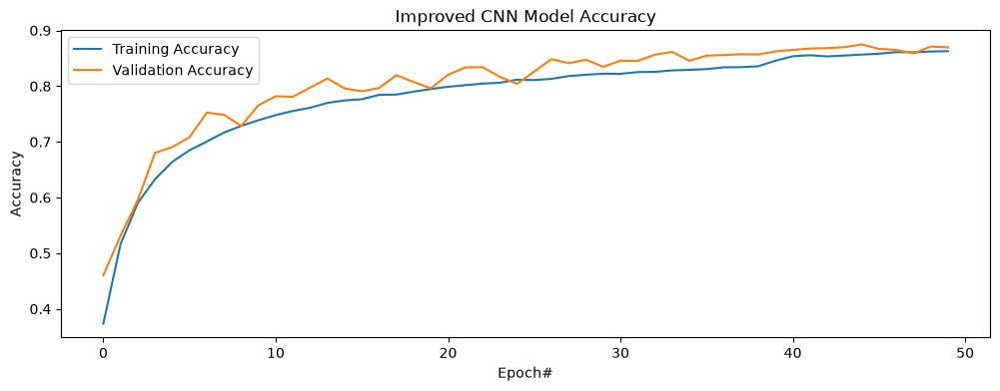

In [43]:
plt.figure(figsize=(12,4))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch#')
plt.ylabel('Accuracy')
plt.title('Improved CNN Model Accuracy')
plt.legend()
plt.show()

### Understanding the effect of `Pooling Layer`

In [44]:
# del base_cnn_test

In [45]:
base_cnn_test = models.Sequential() # placeholder for the base model --> object is the base cnn model

In [46]:
base_cnn_test

<Sequential name=sequential_2, built=False>

In [47]:
### Adding the first convolutional layer (filter layer on top of the input images) --> followed by max pooling
base_cnn_test.add(layers.Conv2D(32, (3,3), activation = 'relu', input_shape = (32,32,3))) #adding a Conv2D layer having 32 filters with kernel/filter size 3x3 grid
base_cnn_test.add(layers.MaxPool2D((2,2))) #adds a maximum pooling layer of size: 2 x 2 --> to reduce the spatial dimensions --> by half in both rows and columns

### Adding the second convolutional layer --> followed by max pooling
base_cnn_test.add(layers.Conv2D(32, (3,3), activation = 'relu')) #adding a second Conv2D layer having 32 filters with kernel/filter size 3x3 grid
base_cnn_test.add(layers.MaxPool2D((2,2))) #adds a 2nd maximum pooling layer of size: 2 x 2 --> to reduce the spatial dimensions --> by half in both rows and columns

### Adding the third convolutional layer (no max pooling after that)
base_cnn_test.add(layers.Conv2D(32, (3,3), activation = 'relu')) #adding a third Conv2D layer having 32 filters with kernel/filter size 3x3 grid

C:\mypython\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [48]:
base_cnn_test.add(layers.Flatten()) #converts a multi-dimensional input coming from CNN into a 1-D vector
base_cnn_test.add(layers.Dense(64, activation = 'relu')) # a dense layer which means fully connected layer having 64 neurons with ReLU as activation function
base_cnn_test.add(layers.Dense(10)) #final layer is the output layer with 10 neurons for 10 classes/categories

In [49]:
base_cnn_test.summary()
# Here the none can be any input value.

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_8 (Conv2D)               │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 13, 13, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 6, 6, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 4, 4, 32)       │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │        32,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 52,874 (206.54 KB)

 Trainable params: 52,874 (206.54 KB)

 Non-trainable params: 0 (0.00 B)